# Phase 1: Exploratory Data Analysis (NASA C-MAPSS FD001)
### Predictive Maintenance & Sensor Degradation Trajectories

This notebook explores the **NASA C-MAPSS (Commercial Modular Aero-Propulsion System Simulation)** dataset. We analyze sensor distributions, detect flat/uninformative signals, inspect engine run-to-failure lifetimes, and establish the relationship between sensor readings and Remaining Useful Life (RUL).

In [1]:
import sys
sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data.loader import load_dataset
from src.data.rul_labeling import add_rul_labels
from src.features.engineering import identify_flat_sensors, get_informative_features
from src.utils.config import SENSOR_COLUMNS, SETTING_COLUMNS, RUL_CAP

sns.set_theme(style='whitegrid')
%matplotlib inline

## 1. Data Loading & Inspection
Load FD001 (100 run-to-failure training engines, single operating condition, single fault mode: HPC degradation).

In [2]:
train_df, test_df, rul_df = load_dataset('FD001')
print(f'Training records: {train_df.shape[0]} across {train_df["unit_number"].nunique()} engines')
print(f'Test trajectories: {test_df.shape[0]} across {test_df["unit_number"].nunique()} engines')
train_df.head()

Training records: 20631 across 100 engines
Test trajectories: 13096 across 100 engines


,unit_number,time_in_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 2. Descriptive Statistics & Identifying Flat Sensors
In FD001, several sensors exhibit zero or near-zero variance across all cycles because they measure variables unaffected by the high-pressure compressor degradation under Sea Level Static conditions. We verify this empirically.

In [3]:
flat_sensors = identify_flat_sensors(train_df, std_threshold=1e-4)
informative_sensors = get_informative_features(train_df)
print(f'Flat/Uninformative Sensors ({len(flat_sensors)}): {flat_sensors}')
print(f'Informative Sensors ({len(informative_sensors)}): {informative_sensors}')

stats = train_df[SENSOR_COLUMNS].describe().T[['mean', 'std', 'min', 'max']]
stats['status'] = ['DROPPED (Flat)' if s in flat_sensors else 'ACTIVE' for s in stats.index]
stats

Flat/Uninformative Sensors (6): ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Informative Sensors (15): ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


,mean,std,min,max,status
sensor_1,518.670000,0.000000e+00,518.6700,518.6700,DROPPED (Flat)
sensor_2,642.680934,5.000533e-01,641.2100,644.5300,ACTIVE
sensor_3,1590.523119,6.131150e+00,1571.0400,1616.9100,ACTIVE
sensor_4,1408.933782,9.000605e+00,1382.2500,1441.4900,ACTIVE
sensor_5,14.620000,5.329200e-15,14.6200,14.6200,DROPPED (Flat)
sensor_6,21.609803,1.388985e-03,21.6000,21.6100,ACTIVE
sensor_7,553.367711,8.850923e-01,549.8500,556.0600,ACTIVE
sensor_8,2388.096652,7.098548e-02,2387.9000,2388.5600,ACTIVE
sensor_9,9065.242941,2.208288e+01,9021.7300,9244.5900,ACTIVE
sensor_10,1.300000,0.000000e+00,1.3000,1.3000,DROPPED (Flat)


> **Interpretation**: Sensors 1, 5, 10, 16, 18, 19 (and setting 3) exhibit standard deviations below 1e-4. Dropping these flat constants prevents multicollinearity in classical regression and redundant parameters in sequence models.

## 3. Engine Lifespan Distribution (Run-to-Failure Cycles)
Each training engine runs until catastrophic failure. The distribution of maximum cycle counts represents the operational lifespan variation.

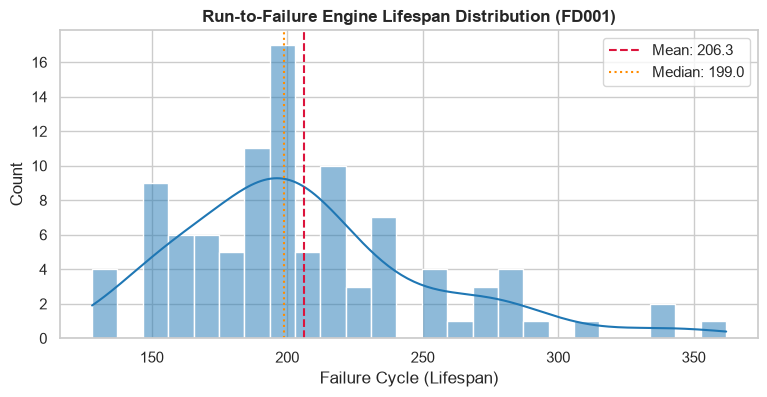

In [4]:
max_cycles = train_df.groupby('unit_number')['time_in_cycles'].max()
plt.figure(figsize=(9, 4))
sns.histplot(max_cycles, bins=25, kde=True, color='#1f77b4')
plt.title('Run-to-Failure Engine Lifespan Distribution (FD001)', fontweight='bold')
plt.xlabel('Failure Cycle (Lifespan)')
plt.axvline(max_cycles.mean(), color='crimson', linestyle='--', label=f'Mean: {max_cycles.mean():.1f}')
plt.axvline(max_cycles.median(), color='darkorange', linestyle=':', label=f'Median: {max_cycles.median():.1f}')
plt.legend()
plt.show()

> **Interpretation**: Engine lifetimes range from 128 to 362 cycles (mean ~206 cycles). This variance motivates our piecewise-linear RUL ceiling (capping at ~125 cycles), as degradation signatures do not develop until the final 100–130 cycles.

## 4. Run-to-Failure Degradation Trajectories
Plot sensor values vs. cycle count for sample engines to visually confirm monotonic degradation signals.

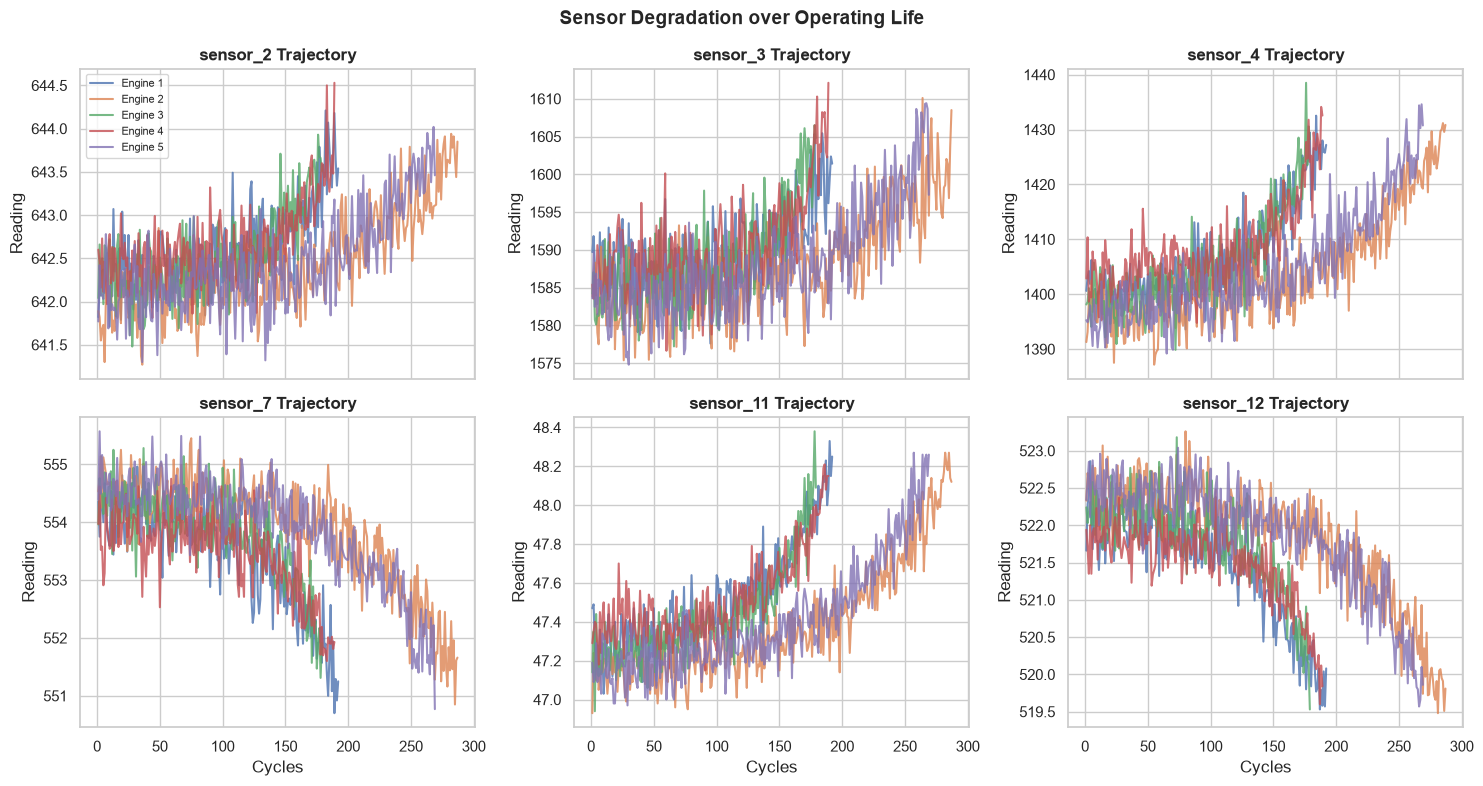

In [5]:
sample_units = [1, 2, 3, 4, 5]
key_sensors = ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_11', 'sensor_12']
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
axes = axes.flatten()
for idx, s in enumerate(key_sensors):
    ax = axes[idx]
    for u in sample_units:
        u_df = train_df[train_df['unit_number'] == u]
        ax.plot(u_df['time_in_cycles'], u_df[s], label=f'Engine {u}', alpha=0.8)
    ax.set_title(f'{s} Trajectory', fontweight='bold')
    ax.set_ylabel('Reading')
    if idx >= 3: ax.set_xlabel('Cycles')
    if idx == 0: ax.legend(fontsize=8)
plt.suptitle('Sensor Degradation over Operating Life', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

> **Interpretation**: Sensors 2, 3, 4, 11 show upward drift as health deteriorates (higher total temperature and pressure ratios), while sensors 7 and 12 decline monotonically. This drift provides a strong regression signal for Remaining Useful Life.

## 5. Sensor vs. Remaining Useful Life (Capped RUL)
Inspect the relationship between sensor readings and remaining life when early-life RUL is capped at 125 cycles.

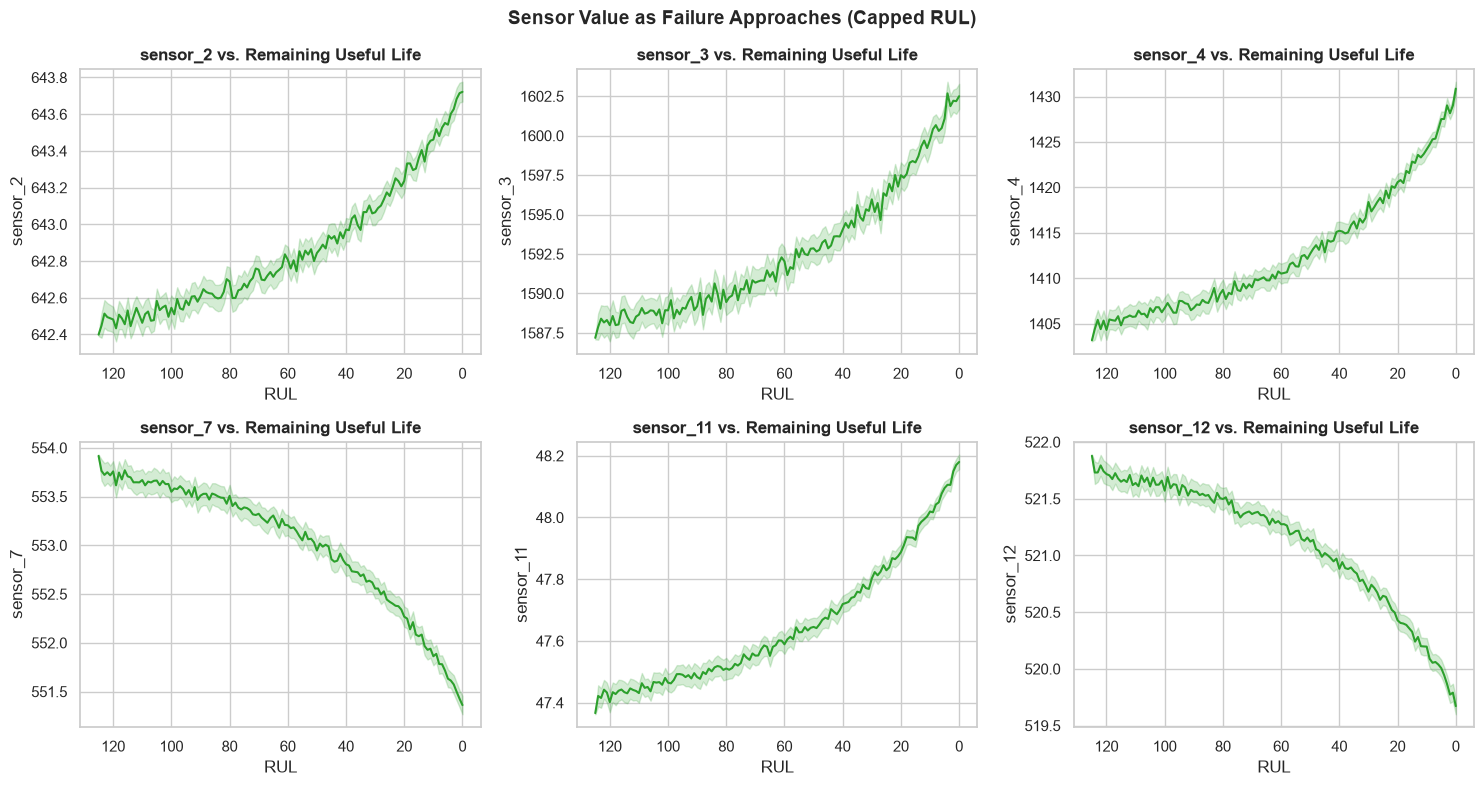

In [6]:
train_df_rul = add_rul_labels(train_df, rul_cap=RUL_CAP, piecewise=True)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for idx, s in enumerate(key_sensors):
    ax = axes[idx]
    sns.lineplot(data=train_df_rul, x='RUL', y=s, ax=ax, color='#2ca02c')
    ax.invert_xaxis()  # 0 is failure on the right
    ax.set_title(f'{s} vs. Remaining Useful Life', fontweight='bold')
plt.suptitle('Sensor Value as Failure Approaches (Capped RUL)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Correlation Heatmap
Examine collinearity across the operational settings and active sensor channels.

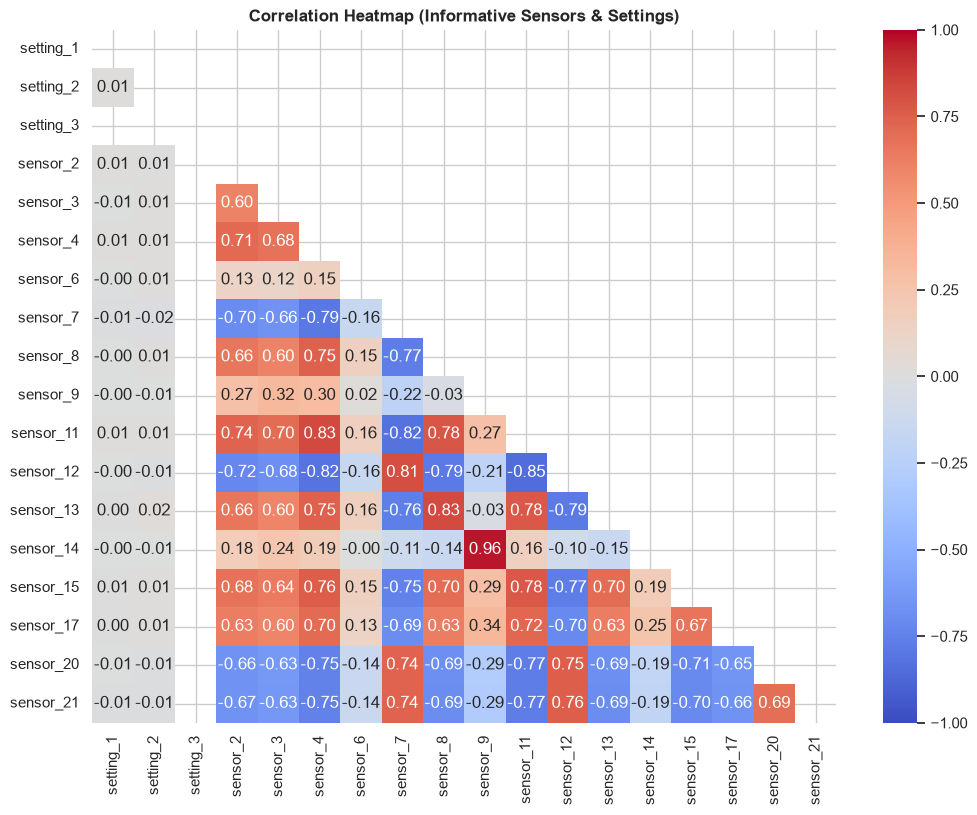

In [7]:
corr_mat = train_df[SETTING_COLUMNS + informative_sensors].corr()
plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(corr_mat, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.2f')
plt.title('Correlation Heatmap (Informative Sensors & Settings)', fontweight='bold')
plt.show()